# Predicting Churn
In this notebook, we will be predicting which of a bank's customers are likely to churn using a random forest method.

## Data Preprocessing

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, roc_auc_score
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import StratifiedKFold, cross_val_score

# import data
# CSV is from https://www.kaggle.com/datasets/radheshyamkollipara/bank-customer-churn/data
df = pd.read_csv("Customer-Churn-Records.csv")
print(df.head())

   RowNumber  CustomerId   Surname  CreditScore Geography  Gender  Age  \
0          1    15634602  Hargrave          619    France  Female   42   
1          2    15647311      Hill          608     Spain  Female   41   
2          3    15619304      Onio          502    France  Female   42   
3          4    15701354      Boni          699    France  Female   39   
4          5    15737888  Mitchell          850     Spain  Female   43   

   Tenure    Balance  NumOfProducts  HasCrCard  IsActiveMember  \
0       2       0.00              1          1               1   
1       1   83807.86              1          0               1   
2       8  159660.80              3          1               0   
3       1       0.00              2          0               0   
4       2  125510.82              1          1               1   

   EstimatedSalary  Exited  Complain  Satisfaction Score Card Type  \
0        101348.88       1         1                   2   DIAMOND   
1        112542.58

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 18 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   RowNumber           10000 non-null  int64  
 1   CustomerId          10000 non-null  int64  
 2   Surname             10000 non-null  str    
 3   CreditScore         10000 non-null  int64  
 4   Geography           10000 non-null  str    
 5   Gender              10000 non-null  str    
 6   Age                 10000 non-null  int64  
 7   Tenure              10000 non-null  int64  
 8   Balance             10000 non-null  float64
 9   NumOfProducts       10000 non-null  int64  
 10  HasCrCard           10000 non-null  int64  
 11  IsActiveMember      10000 non-null  int64  
 12  EstimatedSalary     10000 non-null  float64
 13  Exited              10000 non-null  int64  
 14  Complain            10000 non-null  int64  
 15  Satisfaction Score  10000 non-null  int64  
 16  Card Type       

In [3]:
# remove unnecessary rows
df = df.drop(['CustomerId', 'RowNumber', 'Surname'], axis=1)

# clean cols
df.columns = df.columns.str.strip()

# turn str cols to int
columns_to_encode = df.select_dtypes(include=["str"]).columns.tolist()

label_encoders = {}
for column in columns_to_encode:
    label_encoders[column] = LabelEncoder()
    df[column] = label_encoders[column].fit_transform(df[column])

df.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction Score,Card Type,Point Earned
0,619,0,0,42,2,0.00,1,1,1,101348.88,1,1,2,0,464
1,608,2,0,41,1,83807.86,1,0,1,112542.58,0,1,3,0,456
2,502,0,0,42,8,159660.80,3,1,0,113931.57,1,1,3,0,377
3,699,0,0,39,1,0.00,2,0,0,93826.63,0,0,5,1,350
4,850,2,0,43,2,125510.82,1,1,1,79084.10,0,0,5,1,425


## Training the Model

In [4]:
# separate target and features
target = 'Exited'
X = df.drop(columns=[target])
y = df[target].astype(int)

# split into test/train sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [5]:
# init random forest
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

# fit model
rf_model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [6]:
# predict churn
y_pred = rf_model.predict(X_test)
y_prob = rf_model.predict_proba(X_test)[:, 1]

In [7]:
# evaluate performance
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.9985
ROC-AUC: 0.9988

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1592
           1       1.00      1.00      1.00       408

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000



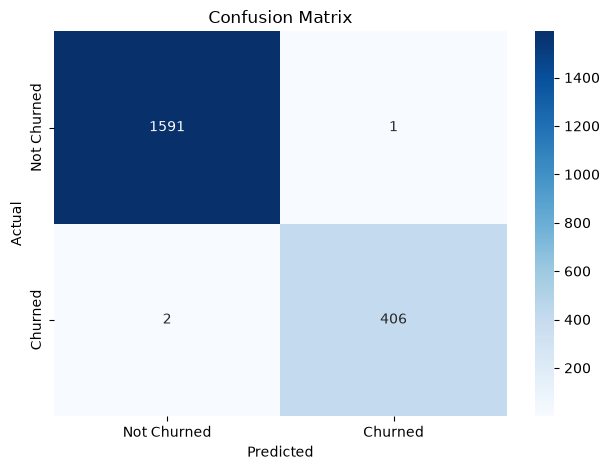

In [8]:
# show confusion matrix
sns.heatmap(
    confusion_matrix(y_test, y_pred),
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Churned", "Churned"],
    yticklabels=["Not Churned", "Churned"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

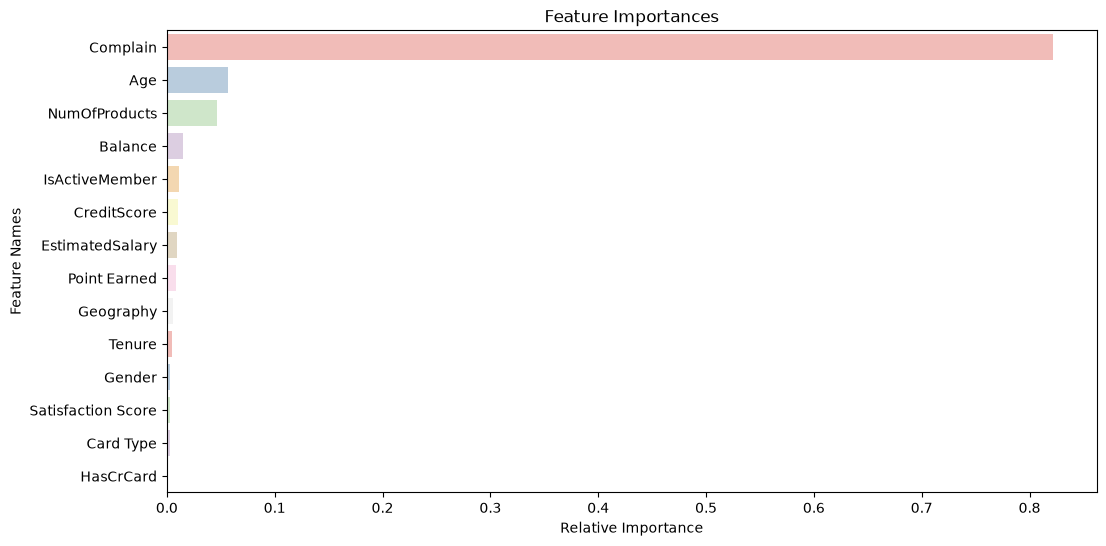

In [9]:
# feature importances
importances = rf_model.feature_importances_
indices = np.argsort(importances)[::-1]

plt.figure(figsize=(12, 6))
sns.barplot(x=importances[indices], y=X.columns[indices], hue=X.columns[indices], palette='Pastel1')
plt.title('Feature Importances')
plt.xlabel('Relative Importance')
plt.ylabel('Feature Names')
plt.show()

In [10]:
# model is very accurate, possible overfitting ?
# drop unimportant features
feature_importance_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': importances
})

mask = (feature_importance_df['Importance'] < 0.01)
features_to_drop = feature_importance_df[mask].sort_values(by='Importance', ascending=False)
print(features_to_drop)

               Feature  Importance
0          CreditScore    0.009892
9      EstimatedSalary    0.009711
13        Point Earned    0.008931
1            Geography    0.005264
4               Tenure    0.005007
2               Gender    0.003065
11  Satisfaction Score    0.002797
12           Card Type    0.002558
7            HasCrCard    0.001399


In [11]:
df = df.drop(features_to_drop['Feature'], axis=1)
df.columns

Index(['Age', 'Balance', 'NumOfProducts', 'IsActiveMember', 'Exited',
       'Complain'],
      dtype='str')

In [12]:
# refit model
X = df.drop(columns=[target])
y = df[target].astype(int)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

rf_model.fit(X_train, y_train)

y_pred = rf_model.predict(X_test)
y_prob = rf_model.predict_proba(X_test)[:, 1]

Accuracy: 0.9985
ROC-AUC: 0.9996

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1592
           1       1.00      1.00      1.00       408

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000



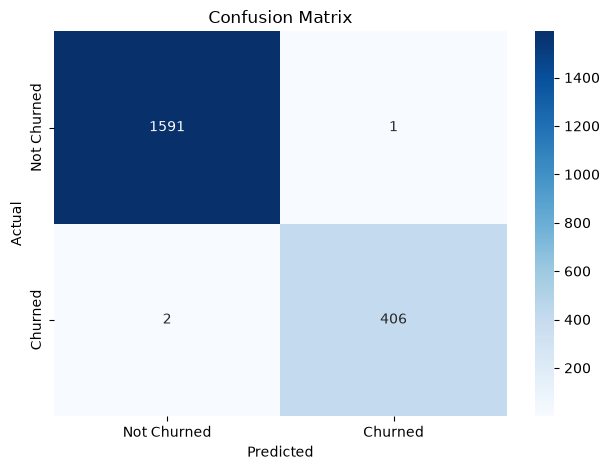

In [13]:
# reevaluate performance
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

sns.heatmap(
    confusion_matrix(y_test, y_pred),
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Churned", "Churned"],
    yticklabels=["Not Churned", "Churned"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

In [14]:
# compare test and train performance as well
train_pred = rf_model.predict(X_train)
test_pred = rf_model.predict(X_test)

print("Train accuracy:", accuracy_score(y_train, train_pred))
print("Test accuracy:", accuracy_score(y_test, test_pred))

print(
    "Train ROC-AUC:",
    roc_auc_score(y_train, rf_model.predict_proba(X_train)[:, 1])
)
print(
    "Test ROC-AUC:",
    roc_auc_score(y_test, rf_model.predict_proba(X_test)[:, 1])
)

Train accuracy: 0.999875
Test accuracy: 0.9985
Train ROC-AUC: 0.9999999518448248
Test ROC-AUC: 0.9995527576608533


In [15]:
# cross validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_val_score(
    rf_model,
    X_train,
    y_train,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1
)

print("Fold AUC scores:", scores)
print("Mean AUC:", scores.mean())
print("Standard deviation:", scores.std())

Fold AUC scores: [1.         0.99901523 0.99951002 0.99791608 0.99789562]
Mean AUC: 0.9988673902784331
Standard deviation: 0.0008446249576089843


## Predict Churn

In [16]:
# get customers still with the bank
predict_df = pd.read_csv("Customer-Churn-Records.csv")
predict_df = predict_df[predict_df['Exited'] == 0]
predict_df.describe()

# save unencoded copy for later
predict_df_copy = predict_df.copy()

In [17]:
# remove unnecessary rows
predict_df = predict_df.drop(['CustomerId', 'RowNumber', 'Surname', 'Exited'], axis=1)
predict_df = predict_df.drop(features_to_drop['Feature'], axis=1)

# clean cols
predict_df.columns = predict_df.columns.str.strip()

# turn str cols to int
columns_to_encode = predict_df.select_dtypes(include=["str"]).columns.tolist()

label_encoders = {}
for column in columns_to_encode:
    label_encoders[column] = LabelEncoder()
    predict_df[column] = label_encoders[column].fit_transform(predict_df[column])

predict_df.head()

,Age,Balance,NumOfProducts,IsActiveMember,Complain
1,41,83807.86,1,1,1
3,39,0.00,2,0,0
4,43,125510.82,1,1,0
6,50,0.00,2,1,0
8,44,142051.07,2,1,0


In [18]:
# make predictions
predictions = rf_model.predict(predict_df)
probabilities = rf_model.predict_proba(predict_df)[:, 1]

results = pd.DataFrame({
    "Churn Probability (%)": (probabilities * 100).round(2),
    "Predicted Exited": predictions
}, index=predict_df.index)

results["Churn Risk"] = np.select(
    [
        results["Churn Probability (%)"] < 30,
        results["Churn Probability (%)"] < 60
    ],
    ["Low", "Medium"],
    default="High"
)

results.value_counts()

Churn Probability (%)  Predicted Exited  Churn Risk
0.00                   0                 Low           7823
1.00                   0                 Low            107
2.00                   0                 Low             11
4.00                   0                 Low              4
33.00                  0                 Medium           2
3.00                   0                 Low              2
43.00                  0                 Medium           1
35.00                  0                 Medium           1
40.00                  0                 Medium           1
41.00                  0                 Medium           1
47.00                  0                 Medium           1
6.00                   0                 Low              1
5.00                   0                 Low              1
30.00                  0                 Medium           1
11.00                  0                 Low              1
7.00                   0                 Low    

In [19]:
# append predictions to df
predict_df_copy = pd.concat([predict_df_copy, results], axis=1)
predict_df_copy.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,...,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction Score,Card Type,Point Earned,Churn Probability (%),Predicted Exited,Churn Risk
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,...,1,112542.58,0,1,3,DIAMOND,456,43.0,0,Medium
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,...,0,93826.63,0,0,5,GOLD,350,0.0,0,Low
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,...,1,79084.10,0,0,5,GOLD,425,0.0,0,Low
6,7,15592531,Bartlett,822,France,Male,50,7,0.00,2,...,1,10062.80,0,0,2,SILVER,206,0.0,0,Low
8,9,15792365,He,501,France,Male,44,4,142051.07,2,...,1,74940.50,0,0,3,GOLD,251,0.0,0,Low


In [20]:
# remove index and save results
predict_df_copy = predict_df_copy.drop(['RowNumber'], axis=1)
predict_df_copy.to_csv("random_forest_predictions.csv", index=False)

## Findings

In [22]:
predict_df_copy['Churn Risk'].value_counts()

Churn Risk
Low       7951
Medium       9
High         2
Name: count, dtype: int64

In [26]:
predict_df_copy[(predict_df_copy['Churn Risk'] == 'Medium') | (predict_df_copy['Churn Risk'] == 'High')]

,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction Score,Card Type,Point Earned,Churn Probability (%),Predicted Exited,Churn Risk
1,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,1,3,DIAMOND,456,43.00,0,Medium
65,15789484,Hammond,751,Germany,Female,36,6,169831.46,2,1,1,27758.36,0,1,5,GOLD,379,33.00,0,Medium
66,15696061,Brownless,581,Germany,Female,34,1,101633.04,1,1,0,110431.51,0,1,3,PLATINUM,469,35.00,0,Medium
67,15641582,Chibugo,735,Germany,Male,43,10,123180.01,2,1,1,196673.28,0,1,3,PLATINUM,683,33.00,0,Medium
68,15638424,Glauert,661,Germany,Female,35,5,150725.53,2,0,1,113656.85,0,1,1,GOLD,770,40.00,0,Medium
171,15613172,Sun,628,Germany,Male,27,5,95826.49,2,1,0,155996.96,0,1,2,SILVER,818,41.00,0,Medium
173,15586310,Ting,578,France,Male,30,4,169462.09,1,1,0,112187.11,0,1,5,DIAMOND,872,47.00,0,Medium
1728,15675320,Leonard,758,Spain,Female,40,5,93499.82,2,0,0,123218.81,0,0,1,DIAMOND,793,30.00,0,Medium
9977,15579969,Mancini,683,France,Female,32,9,0.00,2,1,1,24991.92,0,1,3,SILVER,862,63.22,1,High
9984,15696175,Echezonachukwu,602,Germany,Male,35,7,90602.42,2,1,1,51695.41,0,1,3,GOLD,764,31.20,0,Medium


Applying the model to the bank’s current customer base indicated that the vast majority of existing customers had a low predicted likelihood of churn, which is very good. However, nine customers were classified as being at medium risk of churn, while two were identified as being at high risk.

Customer complaints emerged as the most influential feature in predicting churn. Given the small number of customers identified as being at elevated risk, a targeted retention strategy would be appropriate. The bank should consider contacting these 11 customers individually to address outstanding complaints, resolve any service-related concerns, and improve the likelihood of retaining their business.